# 04 · Model 2 — censored regression on peak area

Model 1 asked a yes/no question and threw away most of the measurement: an area of 9,000 and an
area of 20 both became "does not fly". This model predicts the area itself.

    z = log10(area) = a + x . b + e,    e ~ Normal(0, s),   s^2 = s_model^2 + s_meas^2

The 362 compounds with area 0 are **left-censored**, not missing and not zero: the instrument
says only "below my floor". They enter the likelihood as P(z < limit), so they inform the fit
without being given a value they never had.

Fitted by `scripts/fit_model2.py`; this notebook reads the saved posteriors.

What it should buy us:

1. any detection threshold from one fit, with no refitting
2. an honest split between what the instrument cannot resolve and what structure cannot explain
3. the zeros used as evidence instead of discarded

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT / "scripts"))
from fit_model2 import load, noise_prior, predict, sigma_meas   # noqa: E402

TAG, ADDITIVE, CUTOFF = "chem", "formate", 10_000

prior = noise_prior()
cur, Xdf, z, cens, limit = load([TAG], ADDITIVE)
names = list(Xdf.columns)
area = cur[f"area_{ADDITIVE}"].to_numpy()
y_flies = cur[f"flies_{ADDITIVE}"].to_numpy()
print(f"{len(cur)} compounds | {cens.sum()} censored at log10 area {limit:.2f} | {len(names)} features")
prior

11353 compounds | 362 censored at log10 area 1.30 | 50 features


{'intercept': 0.10798653784549157,
 'slope': -0.01496919227310105,
 'pooled_sd': 0.04290793055882715,
 'n_groups': 2444,
 'min_sigma': 0.02}

In [2]:
def laplace(split, p):
    d = np.load(PROC / f"model2_{TAG}_{ADDITIVE}_{split}_{p}_laplace.npz", allow_pickle=True)
    return {k: d[k] for k in d.files}

def mcmc(split, p):
    return az.from_netcdf(PROC / f"model2_{TAG}_{ADDITIVE}_{split}_{p}_mcmc.nc")

def standardise(split):
    tr = cur[f"split_{split}"].to_numpy() == "train"
    Xa = Xdf.to_numpy(float)
    mu, sd = Xa[tr].mean(0), Xa[tr].std(0)
    return (Xa - mu) / np.where(sd > 1e-9, sd, 1.0), tr

summary = pd.read_csv(PROC / "model2_summary.csv")
summary.round(3)

,prior,posterior,split,features,seconds,RMSE,AUC,log loss,Brier,s_model,divergences
0,gaussian,laplace,random,chem,0.703,0.563,0.849,0.490,0.161,0.648,NaN
1,gaussian,mcmc,random,chem,195.224,0.563,0.849,0.490,0.161,NaN,0.0
2,ard,laplace,random,chem,3.150,0.561,0.849,0.490,0.161,0.648,NaN
3,ard,mcmc,random,chem,308.647,0.562,0.849,0.490,0.161,NaN,0.0
4,gaussian,laplace,cluster,chem,0.733,0.594,0.836,0.504,0.167,0.635,NaN
5,gaussian,mcmc,cluster,chem,200.244,0.594,0.836,0.504,0.167,NaN,0.0
6,ard,laplace,cluster,chem,3.437,0.593,0.836,0.504,0.167,0.635,NaN
7,ard,mcmc,cluster,chem,354.522,0.593,0.836,0.504,0.167,NaN,0.0


## 1. Measurement noise, measured not assumed

The proposal's plan: take the noise prior from the reactivity experiment, where each compound's
no-enzyme control ran in 3-4 wells on the same instrument. The spread inside a group is pure
instrument noise, and those are different compounds, so nothing leaks from the training set.

Two things to check: how big is it, and does it really grow near the detection floor.

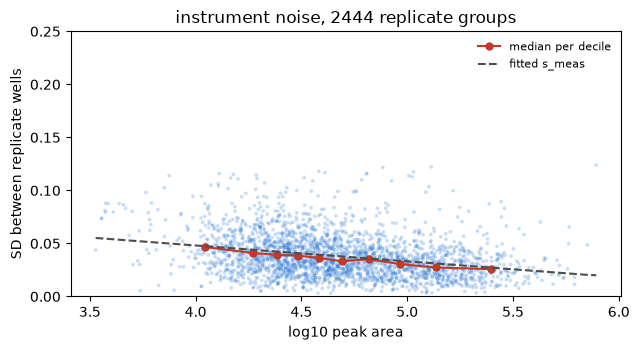

pooled instrument noise: 0.043 log10 units (1.10x in linear area)


In [3]:
wells = pd.read_csv(ROOT / "data" / "raw" / "reactivity_wells.tsv", sep="\t")
ctl = wells[wells["condition"].str.lower() == "control"]
rep = []
for _, s in ctl.groupby(["ocnt_batch", "enzyme"])["area"]:
    pos = s[s > 0]
    if len(pos) >= 3:
        lg = np.log10(pos)
        rep.append({"level": lg.mean(), "sd": lg.std(ddof=1)})
rep = pd.DataFrame(rep)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(rep["level"], rep["sd"], s=7, alpha=0.25, color="#2a78d6", edgecolors="none")
q = pd.qcut(rep["level"], 10)
binned = rep.groupby(q, observed=True).agg(level=("level", "mean"), sd=("sd", "median"))
ax.plot(binned["level"], binned["sd"], "o-", color="#c0392b", ms=5, label="median per decile")
grid = np.linspace(rep["level"].min(), rep["level"].max(), 50)
ax.plot(grid, sigma_meas(grid, prior), "--", color="0.3", lw=1.5, label="fitted s_meas")
ax.set_xlabel("log10 peak area"); ax.set_ylabel("SD between replicate wells")
ax.set_ylim(0, 0.25); ax.legend(frameon=False, fontsize=8)
ax.set_title(f"instrument noise, {len(rep)} replicate groups")
plt.tight_layout(); plt.show()

print(f"pooled instrument noise: {prior['pooled_sd']:.3f} log10 units "
      f"({10 ** prior['pooled_sd']:.2f}x in linear area)")

## 2. Where the uncertainty actually lives

The proposal splits predictive uncertainty into measurement noise and model uncertainty. Having
fitted both, the split is lopsided in a way worth stating plainly.

In [4]:
Xs, tr = standardise("random")
te = ~tr
fit = laplace("random", "ard")
mu_hat, p_fly, mu_sd = predict(fit, Xs[te], prior, cutoff=CUTOFF)

parts = pd.DataFrame({
    "source": ["instrument (s_meas)", "unexplained by structure (s_model)", "which molecule this is (sd of mu*)"],
    "log10 units": [float(sigma_meas(mu_hat, prior).mean()), float(np.exp(fit["mean"][-1])), float(np.median(mu_sd))],
})
parts["fold change in area"] = 10 ** parts["log10 units"]
parts.round(3)

,source,log10 units,fold change in area
0,instrument (s_meas),0.049,1.120
1,unexplained by structure (s_model),0.648,4.450
2,which molecule this is (sd of mu*),0.037,1.089


`s_model` is more than ten times the instrument noise. A perfect mass spectrometer would barely
move these predictions — the limit is that **structure alone does not pin down peak area**. That
is an argument for better representations (neural fingerprints, Model 3's kernel), not better
instruments, and it is worth saying in the report because the proposal's framing implies the two
noise sources might be comparable.

## 3. Does the fit describe the data?

Three checks before trusting anything downstream: predicted against observed, residuals against
the fitted level, and whether the censored compounds really do sit at the bottom.

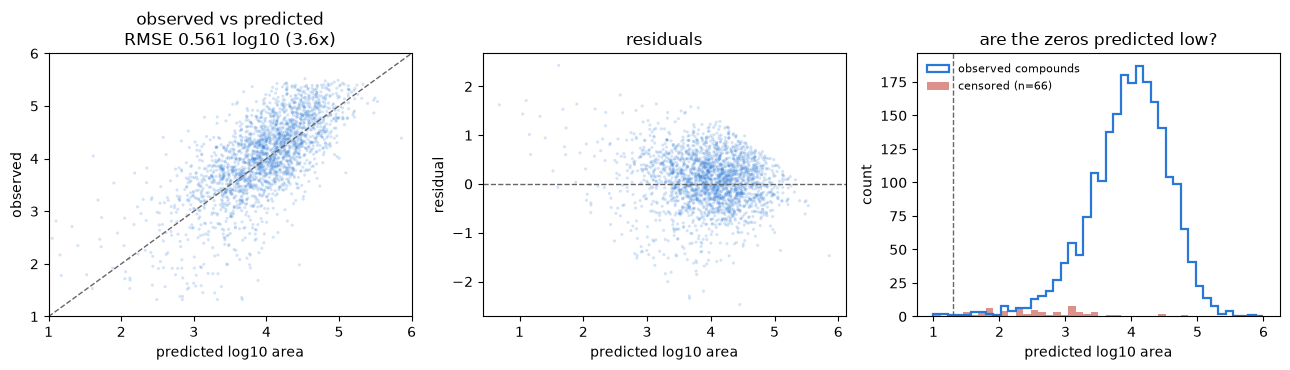

median prediction: observed 4.01, censored 2.52


In [5]:
obs = ~cens[te]
z_te = z[te]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

ax = axes[0]
ax.scatter(mu_hat[obs], z_te[obs], s=5, alpha=0.2, color="#2a78d6", edgecolors="none")
lim = [1, 6]
ax.plot(lim, lim, "--", color="0.4", lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
rmse = float(np.sqrt(np.mean((z_te[obs] - mu_hat[obs]) ** 2)))
ax.set_title(f"observed vs predicted\nRMSE {rmse:.3f} log10 ({10 ** rmse:.1f}x)")
ax.set_xlabel("predicted log10 area"); ax.set_ylabel("observed")

ax = axes[1]
resid = z_te[obs] - mu_hat[obs]
ax.scatter(mu_hat[obs], resid, s=5, alpha=0.2, color="#2a78d6", edgecolors="none")
ax.axhline(0, color="0.4", lw=1, ls="--")
ax.set_xlabel("predicted log10 area"); ax.set_ylabel("residual")
ax.set_title("residuals")

ax = axes[2]
bins = np.linspace(1, 6, 45)
ax.hist(mu_hat[obs], bins=bins, histtype="step", lw=1.6, color="#2a78d6", label="observed compounds")
ax.hist(mu_hat[~obs], bins=bins, histtype="stepfilled", color="#c0392b", alpha=0.55,
        label=f"censored (n={int((~obs).sum())})")
ax.axvline(limit, ls="--", color="0.4", lw=1)
ax.set_xlabel("predicted log10 area"); ax.set_ylabel("count")
ax.legend(frameon=False, fontsize=8); ax.set_title("are the zeros predicted low?")

plt.tight_layout(); plt.show()
print(f"median prediction: observed {np.median(mu_hat[obs]):.2f}, censored {np.median(mu_hat[~obs]):.2f}")

## 4. The payoff: any threshold, one fit

`CUTOFF` never enters the fit. It appears only here, at prediction time:

    P(flies | x*, T) = Phi( (mu* - log10 T) / sqrt(s_eps^2 + s*^2) )

So if the lab moves its threshold, nothing is retrained. Model 1 would need a new fit per
threshold, because the threshold is baked into its labels.

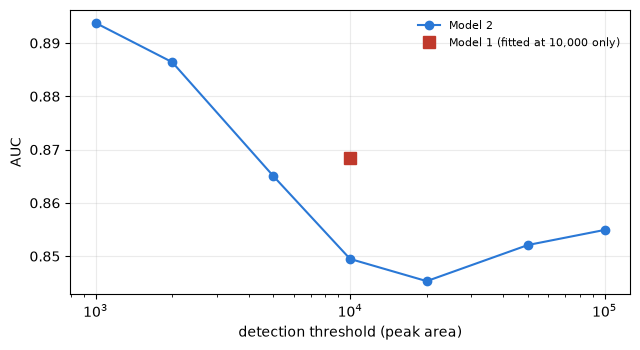

,cutoff,% flying,AUC,log loss
0,1000,0.886,0.894,0.232
1,2000,0.828,0.886,0.310
2,5000,0.686,0.865,0.436
3,10000,0.529,0.849,0.490
4,20000,0.370,0.845,0.470
5,50000,0.191,0.852,0.352
6,100000,0.089,0.855,0.229


In [6]:
rows = []
for T in [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000]:
    _, p, _ = predict(fit, Xs[te], prior, cutoff=T)
    truth = (area[te] > T).astype(int)
    rows.append({"cutoff": T, "% flying": truth.mean(),
                 "AUC": roc_auc_score(truth, p),
                 "log loss": log_loss(truth, np.clip(p, 1e-6, 1 - 1e-6))})
thresholds = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogx(thresholds["cutoff"], thresholds["AUC"], "o-", color="#2a78d6", label="Model 2")
m1 = pd.read_csv(PROC / "model1_summary.csv").query(
    "prior=='ard' and posterior=='laplace' and split=='random'")["AUC"].iloc[0]
ax.plot(CUTOFF, m1, "s", ms=9, color="#c0392b", label="Model 1 (fitted at 10,000 only)")
ax.set_xlabel("detection threshold (peak area)"); ax.set_ylabel("AUC")
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

thresholds.round(3)

Model 1 wins at 10,000 — it was trained for exactly that question, and Model 2 was not. The
trade is one accuracy point at the lab's current threshold for a model that answers every other
threshold for free.

## 5. Does Laplace match MCMC here?

Model 1's ARD fit had intervals about a third too narrow. The same check, on this model.

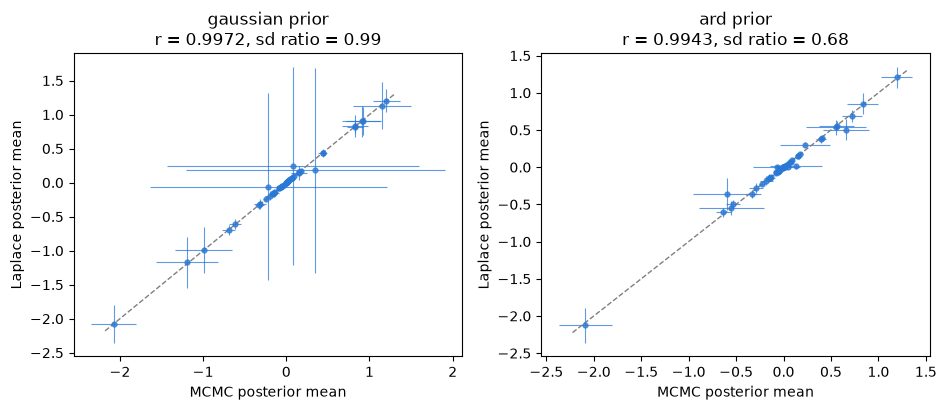

gaussian  r_hat <= 1.008  ess >= 381  divergences 0  s_model: laplace 0.6479 vs mcmc 0.6498
ard       r_hat <= 1.007  ess >= 742  divergences 0  s_model: laplace 0.6483 vs mcmc 0.6500


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, p in zip(axes, ["gaussian", "ard"]):
    lap, mc = laplace("random", p), mcmc("random", p)
    b_mc = mc.posterior["b"].to_numpy().reshape(-1, len(names))
    lm, ls = lap["mean"][1:-1], np.sqrt(np.diag(lap["cov"])[1:-1])
    ax.errorbar(b_mc.mean(0), lm, xerr=b_mc.std(0), yerr=ls, fmt="o", ms=3.5,
                lw=0.8, alpha=0.75, color="#2a78d6")
    lo = min(lm.min(), b_mc.mean(0).min()) - 0.1
    hi = max(lm.max(), b_mc.mean(0).max()) + 0.1
    ax.plot([lo, hi], [lo, hi], "--", color="0.5", lw=1)
    ax.set_title(f"{p} prior\nr = {np.corrcoef(b_mc.mean(0), lm)[0, 1]:.4f}, "
                 f"sd ratio = {np.mean(ls / b_mc.std(0)):.2f}")
    ax.set_xlabel("MCMC posterior mean"); ax.set_ylabel("Laplace posterior mean")
plt.tight_layout(); plt.show()

for p in ["gaussian", "ard"]:
    mc = mcmc("random", p)
    d = az.summary(mc, var_names=["b"], kind="diagnostics")
    print(f"{p:9s} r_hat <= {d['r_hat'].max():.3f}  ess >= {d['ess_bulk'].min():.0f}  "
          f"divergences {int(mc.sample_stats['diverging'].sum())}  "
          f"s_model: laplace {np.exp(laplace('random', p)['mean'][-1]):.4f} "
          f"vs mcmc {float(mc.posterior['s_model'].mean()):.4f}")

With the fixed Gaussian prior the agreement is near-exact, including the widths. ARD again gives
intervals about a third narrow — the funnel in its posterior is not a shape a Gaussian can take,
and that is a property of the ARD prior rather than of either model. Centres, predictions and
`s_model` all agree, so the Laplace fit stays usable; only per-coefficient intervals under ARD
need the MCMC numbers.

## 6. Model 1 vs Model 2 vs the baseline

All on the same frozen test rows, the same 50 features, scored at the lab's 10,000 threshold.

In [8]:
rows = []
rf = pd.read_csv(PROC / "baseline_rf.csv")
m1 = pd.read_csv(PROC / "model1_summary.csv")

for split in ["random", "cluster"]:
    Xs_s, tr_s = standardise(split)
    te_s = ~tr_s
    _, p2, _ = predict(laplace(split, "ard"), Xs_s[te_s], prior, cutoff=CUTOFF)
    yt = y_flies[te_s]
    r = rf.query("split == @split and features == 'chem'").iloc[0]
    a = m1.query("prior=='ard' and posterior=='laplace' and split == @split").iloc[0]
    rows += [
        {"split": split, "model": "random forest", "AUC": r["AUC"], "log loss": r["log loss"], "Brier": r["Brier"]},
        {"split": split, "model": "Model 1 (logistic)", "AUC": a["AUC"], "log loss": a["log loss"], "Brier": a["Brier"]},
        {"split": split, "model": "Model 2 (censored)", "AUC": roc_auc_score(yt, p2),
         "log loss": log_loss(yt, np.clip(p2, 1e-6, 1 - 1e-6)), "Brier": brier_score_loss(yt, p2)},
    ]
pd.DataFrame(rows).set_index(["split", "model"]).round(3)

AUC  log loss  Brier
split   model                                     
random  random forest       0.846     0.486  0.161
        Model 1 (logistic)  0.868     0.455  0.148
        Model 2 (censored)  0.849     0.490  0.161
cluster random forest       0.838     0.498  0.165
        Model 1 (logistic)  0.846     0.485  0.160
        Model 2 (censored)  0.836     0.504  0.167

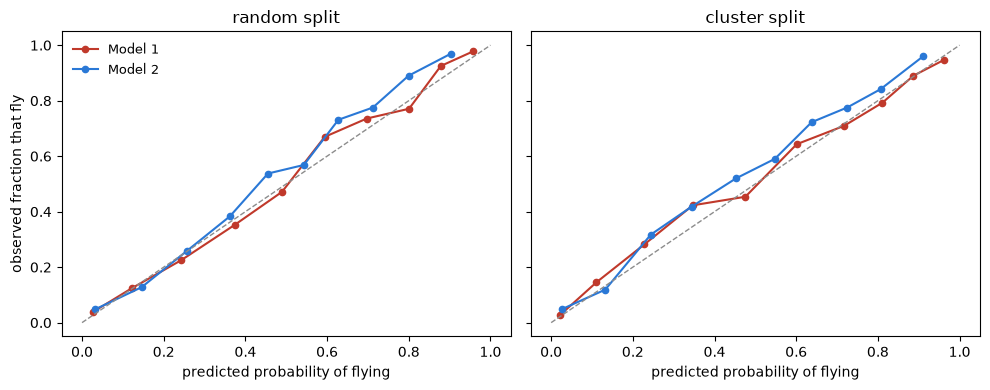

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, split in zip(axes, ["random", "cluster"]):
    Xs_s, tr_s = standardise(split)
    te_s = ~tr_s
    _, p2, _ = predict(laplace(split, "ard"), Xs_s[te_s], prior, cutoff=CUTOFF)
    p1 = np.load(PROC / f"model1_chem_{ADDITIVE}_{split}_ard_laplace.npz")["test_pred"]
    for p, lab, c in [(p1, "Model 1", "#c0392b"), (p2, "Model 2", "#2a78d6")]:
        frac, pred = calibration_curve(y_flies[te_s], p, n_bins=10, strategy="quantile")
        ax.plot(pred, frac, "o-", ms=4.5, lw=1.5, color=c, label=lab)
    ax.plot([0, 1], [0, 1], "--", color="0.55", lw=1)
    ax.set_title(f"{split} split"); ax.set_xlabel("predicted probability of flying")
axes[0].set_ylabel("observed fraction that fly"); axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### Where this leaves the project

- Model 2 does what it was for: the zeros are used, the threshold is free, and the two noise
  sources are separated and quantified.
- At the lab's fixed threshold Model 1 remains the better classifier, so the two are
  complementary rather than one replacing the other.
- `s_model` dwarfs the instrument noise, which says the next gain comes from a better molecular
  representation. That is Model 3's Tanimoto kernel, and after it the neural fingerprints.